# Step 6 — Specification

> Full prompt for this step, reproduced verbatim (capstone_project_rules.md code-style rule:
> each notebook opens with its own spec so it is self-contained).

STEP 6 — Regime detection v1: K-means on market conditions

Read capstone_project_rules.md first. Implement ONLY this step, in notebooks/06_regime.ipynb.
First cell: this entire prompt in markdown, titled "# Step 6 — Specification".

## Goal
A point-in-time regime label (CALM / NORMAL / STRESS) for each month-end of
the step-3 schedule, produced by K-means on market-condition variables.
This label will scale total exposure in step 7 (calm 100% / normal 80% /
stress 50%, freed capital to SHY). K-means is the v1 baseline; HMM (step 10)
must beat it to replace it.

## Features (weekly, computed from data of the 7 ETFs + SPY only where noted)
1. realized_vol: trailing 8-week std of SPY weekly returns, annualized
2. trailing_ret: trailing 13-week cumulative SPY return
3. avg_corr: average pairwise correlation of the 4 equity ETFs over
   trailing 26 weeks
Standardize features (z-score) — but see the point-in-time rule below.

## Point-in-time protocol (CRITICAL — capstone_project_rules.md rules 1-2)
For each month-end T (walk-forward, expanding):
  a. Use feature history from inception up to T ONLY.
  b. Fit the z-score scaler on data up to T. Fit K-means (k=3, n_init=20,
     random_state fixed) on data up to T.
  c. Label ONLY month T with that model. Store (T, label). Discard the
     model's relabeling of the past (diary rule: each month written once).
  d. Map the 3 clusters to CALM/NORMAL/STRESS by sorting cluster centers
     on the realized_vol dimension (lowest vol = CALM, highest = STRESS).
     Do this mapping at every T from that T's own centers — cluster ids
     are arbitrary and can permute between refits.
Start when >= 5 years of feature history exist (~2012 given VEA-dependent
avg_corr starts ~2008). Expanding window, refit monthly.

## Stability layer (avoid regime ping-pong)
Apply hysteresis on the stored point-in-time labels: the OFFICIAL regime
only changes when the raw K-means label differs from the current official
regime for 2 consecutive month-ends. Store both series: raw and official.

## Outputs
outputs/regime_v1.parquet: date, raw_label, official_label, plus the three
feature values at each T.

## Diagnostics
1. Timeline chart: official regime as colored background (green/gray/red)
   with SPY cumulative return on top. Eyeball: 2015-16, 2018Q4, 2020,
   2022 should show NORMAL/STRESS; 2013-14, 2017, 2021 mostly CALM.
2. Table: % of months per regime (expect roughly 40-50% calm, 30-40%
   normal, 10-20% stress — flag if stress > 30% or < 5%).
3. Number of official regime CHANGES per year (expect ~1-4; flag if > 6).
4. Detection lag check for 2020: print raw and official labels for
   2020-01 through 2020-06 month by month.
5. Compare raw vs official: how many ping-pong flips did hysteresis remove?

## Sanity notes
- No exposure scaling applied yet (step 7). Labels only.
- Weekly data for features; monthly labeling.
- If a refit ever yields a degenerate cluster (< 5 points), print a
  warning and carry forward the previous month's label.


## 0 — Setup & features

Three weekly market-condition features. Note on `avg_corr`: it is the average of
the **6 pairwise correlations among all 4 equity ETFs**, so it only exists once
VEA (2007-08) has ≥26 weeks of history — i.e. from ~2008. We use
`mean(skipna=False)` so a missing pair makes the feature NaN rather than silently
averaging a subset (which would let the series start too early and change its
meaning).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

EQ = ["SPY", "VEA", "XLE", "XLU"]
REGIMES = ["CALM", "NORMAL", "STRESS"]
COLMAP = {"CALM": "#2ca02c", "NORMAL": "#9e9e9e", "STRESS": "#d62728"}
ALPHA_BG = 0.25       # regime background shading opacity
MIN_HISTORY = 260     # >= 5 years of weekly features before labeling
RS = 42               # fixed random_state

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

rw = pd.read_parquet(DATA_DIR / "returns_weekly.parquet")

realized_vol = rw["SPY"].rolling(8).std() * np.sqrt(52)
trailing_ret = (1 + rw["SPY"]).rolling(13).apply(np.prod, raw=True) - 1
pairs_idx = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
pair_corrs = [rw[EQ[a]].rolling(26).corr(rw[EQ[b]]) for a, b in pairs_idx]
avg_corr = pd.concat(pair_corrs, axis=1).mean(axis=1, skipna=False)   # requires all 4 ETFs

feat = pd.DataFrame({"realized_vol": realized_vol,
                     "trailing_ret": trailing_ret,
                     "avg_corr": avg_corr}).dropna()

last_obs = feat.index.max()   # bound by the last REAL weekly feature observation, not
                               # wall-clock "today" — same point-in-time fix as Steps 3/4
                               # (a calendar month-end with no data behind it isn't a
                               # valid point-in-time snapshot; it would just restate the
                               # prior window as if new information had arrived).
month_ends = pd.date_range(feat.index.min(), last_obs, freq="ME")
schedule = [T for T in month_ends if (feat.index <= T).sum() >= MIN_HISTORY]

print(f"weekly features: {len(feat)} rows, {feat.index.min().date()} -> {feat.index.max().date()}")
print(f"labeled schedule: {len(schedule)} month-ends, {schedule[0].date()} -> {schedule[-1].date()}")

weekly features: 968 rows, 2008-01-25 -> 2026-08-07
labeled schedule: 163 month-ends, 2013-01-31 -> 2026-07-31


## 1 — Walk-forward point-in-time labeling

For each month-end T we fit the scaler and K-means on the **weekly feature history
up to T only** (expanding window), then label **only** month T — the cluster of
its most recent weekly feature vector. Clusters are mapped to CALM/NORMAL/STRESS
by sorting the cluster centers on the `realized_vol` axis (lowest vol → CALM), done
fresh each T because cluster ids permute between refits (rules 1–2: no lookahead,
no retrospective relabeling). A degenerate refit (any cluster < 5 points) triggers
a warning and carry-forward of the previous label.

In [2]:
raw_label, feat_at_T = {}, {}
prev, degenerate = None, 0

for T in schedule:
    hist = feat[feat.index <= T]
    scaler = StandardScaler().fit(hist.values)
    X = scaler.transform(hist.values)
    km = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X)

    sizes = np.bincount(km.labels_, minlength=3)
    if sizes.min() < 5:
        degenerate += 1
        lab = prev if prev is not None else "NORMAL"
        print(f"WARNING {T.date()}: degenerate cluster (sizes={sizes}) -> carry forward '{lab}'")
    else:
        # map clusters -> regimes by realized_vol center (feature column 0), low->high
        order = np.argsort(km.cluster_centers_[:, 0])
        cid_to_regime = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
        lab = cid_to_regime[km.labels_[-1]]     # last training point = month T's week

    raw_label[T] = lab
    feat_at_T[T] = hist.iloc[-1]
    prev = lab

raw_series = pd.Series([raw_label[T] for T in schedule], index=pd.DatetimeIndex(schedule))
print(f"\nlabeled {len(raw_series)} months; degenerate refits: {degenerate}")
print("raw label counts:", raw_series.value_counts().reindex(REGIMES).to_dict())


labeled 163 months; degenerate refits: 0
raw label counts: {'CALM': 115, 'NORMAL': 40, 'STRESS': 8}


## 2 — Hysteresis (official regime)

To avoid month-to-month ping-pong, the **official** regime only switches after the
raw label has disagreed with it for **2 consecutive month-ends** (and both point to
the same new regime).

In [3]:
official = [raw_series.iloc[0]]
cur = raw_series.iloc[0]
for t in range(1, len(raw_series)):
    if raw_series.iloc[t] == raw_series.iloc[t - 1] and raw_series.iloc[t] != cur:
        cur = raw_series.iloc[t]
    official.append(cur)
official_series = pd.Series(official, index=raw_series.index)

raw_changes = int((raw_series.values[1:] != raw_series.values[:-1]).sum())
off_changes = int((official_series.values[1:] != official_series.values[:-1]).sum())
print(f"raw regime changes: {raw_changes} | official changes: {off_changes} | "
      f"ping-pong flips removed by hysteresis: {raw_changes - off_changes}")

raw regime changes: 21 | official changes: 13 | ping-pong flips removed by hysteresis: 8


## 2b — Asymmetric hysteresis (`official_v2`)

A second official series with **asymmetric** hysteresis — react fast to danger,
exit slowly:

- **Enter STRESS immediately** on a single raw STRESS signal (1 signal).
- **Exit STRESS only after 2 consecutive non-STRESS** raw labels.
- **CALM ↔ NORMAL** transitions keep the symmetric 2-consecutive rule.

This directly targets the Step-6 finding that the symmetric v1 both under-calls and
lags stress (recall v1 delayed the 2020 entry by a month). We keep both series.

In [4]:
def asymmetric_official(raw):
    lab = list(raw.values)
    cur = lab[0]
    out = [cur]
    for t in range(1, len(lab)):
        r = lab[t]
        if r == "STRESS":
            cur = "STRESS"                       # immediate enter on 1 signal
        elif cur == "STRESS":
            if lab[t - 1] != "STRESS":           # 2 consecutive non-STRESS -> exit
                cur = r
            # else only 1 non-STRESS so far -> stay STRESS
        else:
            if r != cur and r == lab[t - 1]:     # CALM<->NORMAL: symmetric 2-consecutive
                cur = r
        out.append(cur)
    return pd.Series(out, index=raw.index)

official_v2 = asymmetric_official(raw_series)
v2_changes = int((official_v2.values[1:] != official_v2.values[:-1]).sum())
print(f"regime changes -> raw: {raw_changes} | official (v1 symmetric): {off_changes} | "
      f"official_v2 (asymmetric): {v2_changes}")
print("official_v2 label counts:", official_v2.value_counts().reindex(REGIMES).to_dict())

regime changes -> raw: 21 | official (v1 symmetric): 13 | official_v2 (asymmetric): 16
official_v2 label counts: {'CALM': 114, 'NORMAL': 36, 'STRESS': 13}


## 3 — Save `outputs/regime_v1.parquet`

Point-in-time: `date`, `raw_label`, `official_label` (v1 symmetric), `official_v2`
(asymmetric), and the three feature values as of each T.

In [5]:
out = pd.DataFrame({
    "date": pd.DatetimeIndex(schedule),
    "raw_label": raw_series.values,
    "official_label": official_series.values,
    "official_v2": official_v2.values,
    "realized_vol": [feat_at_T[T]["realized_vol"] for T in schedule],
    "trailing_ret": [feat_at_T[T]["trailing_ret"] for T in schedule],
    "avg_corr": [feat_at_T[T]["avg_corr"] for T in schedule],
})
p = OUT_DIR / "regime_v1.parquet"
out.to_parquet(p, index=False)
print(f"saved {p.name}  rows={len(out)}  {p.stat().st_size/1024:.1f} KB")
print(out.head(3).to_string(index=False))

saved regime_v1.parquet  rows=163  10.4 KB
      date raw_label official_label official_v2  realized_vol  trailing_ret  avg_corr
2013-01-31      CALM           CALM        CALM      0.131535      0.070504  0.687442
2013-02-28      CALM           CALM        CALM      0.106513      0.082188  0.683947
2013-03-31      CALM           CALM        CALM      0.054462      0.123808  0.696686


# Diagnostics

### D1 — Regime timeline vs SPY

Official regime as colored background (green CALM / gray NORMAL / red STRESS) with
SPY cumulative return on top. Eyeball check: 2015–16, 2018Q4, 2020, 2022 should
show NORMAL/STRESS; 2013–14, 2017, 2021 mostly CALM.

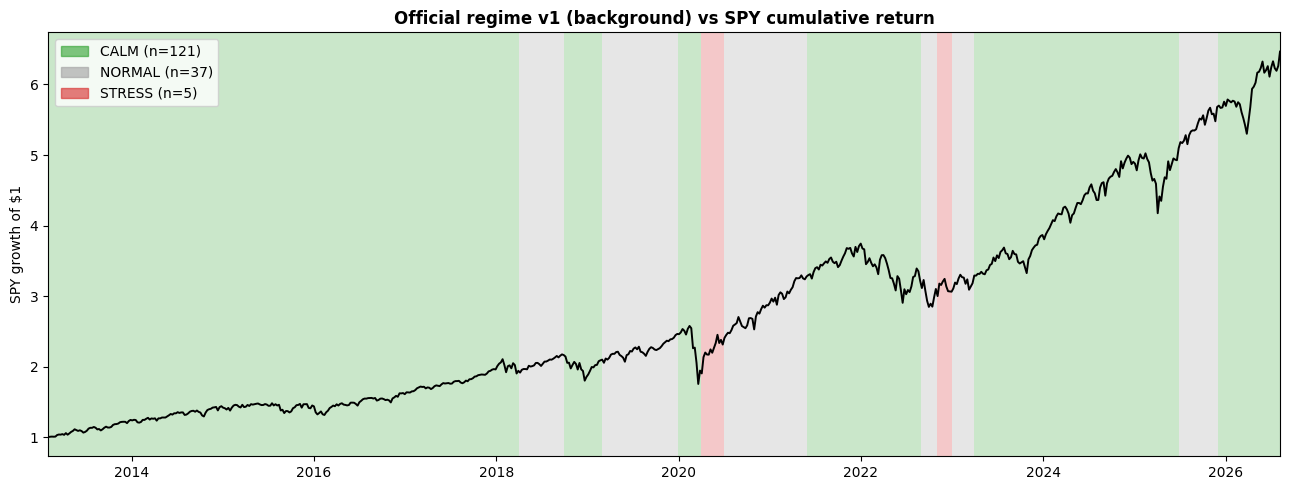

v1 spans drawn per regime: {'CALM': 121, 'NORMAL': 37, 'STRESS': 5}
v1 STRESS bands: 5 -> [datetime.date(2020, 3, 31), datetime.date(2020, 4, 30), datetime.date(2020, 5, 31), datetime.date(2022, 10, 31), datetime.date(2022, 11, 30)]


In [6]:
spy_cum = (1 + rw["SPY"][rw.index >= schedule[0]]).cumprod()
idx = official_series.index   # kept for later cells (changes-per-year)

def regime_timeline(official, title):
    """Timeline with regime background bands.

    IMPORTANT: draw the SPY line with matplotlib's native ax.plot(index, values),
    NOT pandas Series.plot(). Pandas installs its own date-unit converter, which
    places the line on x-coordinates that do NOT match the matplotlib date floats
    used by ax.axvspan(Timestamp, ...). That mismatch pushed the spans off-screen
    and left the background white regardless of alpha. Using ax.plot keeps the line
    and the spans in the same date coordinate system, so the bands render.
    """
    ix = official.index
    fig, ax = plt.subplots(figsize=(13, 5))
    counts = {r: 0 for r in REGIMES}
    for i, T in enumerate(ix):
        end = ix[i + 1] if i + 1 < len(ix) else spy_cum.index[-1]
        reg = official.iloc[i]
        ax.axvspan(T, end, color=COLMAP[reg], alpha=ALPHA_BG, zorder=0, linewidth=0)
        counts[reg] += 1
    ax.plot(spy_cum.index, spy_cum.values, color="black", linewidth=1.4, zorder=2)
    ax.set_xlim(ix[0], spy_cum.index[-1])
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("SPY growth of $1"); ax.set_xlabel("")
    ax.legend(handles=[Patch(color=COLMAP[r], alpha=0.6, label=f"{r} (n={counts[r]})") for r in REGIMES],
              loc="upper left")
    plt.tight_layout(); plt.show()
    return counts

counts_v1 = regime_timeline(official_series, "Official regime v1 (background) vs SPY cumulative return")
print("v1 spans drawn per regime:", counts_v1)
stress_v1 = [T.date() for T in idx if official_series.loc[T] == "STRESS"]
print(f"v1 STRESS bands: {len(stress_v1)} ->", stress_v1)

### D2 — Regime frequency

Expect roughly 40–50% CALM, 30–40% NORMAL, 10–20% STRESS. Flag if STRESS > 30%
or < 5%. We show both the raw K-means share and the post-hysteresis official
share (hysteresis removes brief stress spikes, lowering the STRESS share further).

In [7]:
raw_pct = (raw_series.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100).round(1)
off_pct = (official_series.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100).round(1)
print(pd.DataFrame({"raw_%": raw_pct, "official_%": off_pct}).to_string())
stress = off_pct["STRESS"]
print(f"\nofficial STRESS = {stress:.1f}%  ->",
      "FLAG (outside 5-30%)" if (stress > 30 or stress < 5) else "within expected 5-30%")

        raw_%  official_%
CALM     70.6        74.2
NORMAL   24.5        22.7
STRESS    4.9         3.1

official STRESS = 3.1%  -> FLAG (outside 5-30%)


### D3 — Official regime changes per year

Expect ~1–4 per year; flag any year > 6.

In [8]:
chg_dates = idx[1:][official_series.values[1:] != official_series.values[:-1]]
per_year = pd.Series(1, index=pd.DatetimeIndex(chg_dates)).groupby(lambda d: d.year).sum()
per_year = per_year.reindex(range(idx[0].year, idx[-1].year + 1), fill_value=0)
print("official regime changes per year:")
print(per_year.to_string())
flagged = per_year[per_year > 6]
print("\n" + ("FLAG years > 6: " + ", ".join(map(str, flagged.index)) if len(flagged) else "no year exceeds 6 changes."))

official regime changes per year:
2013    0
2014    0
2015    0
2016    0
2017    0
2018    2
2019    2
2020    2
2021    1
2022    3
2023    1
2024    0
2025    2
2026    0

no year exceeds 6 changes.


### D4 — Detection lag around the 2020 crash

Raw vs official month by month, 2020-01 → 2020-06. Hysteresis costs ~1 month of
lag entering a new regime — visible here.

In [9]:
mask = (raw_series.index >= "2020-01-01") & (raw_series.index <= "2020-06-30")
lag = pd.DataFrame({"raw": raw_series[mask], "official": official_series[mask]})
lag.index = lag.index.date
print(lag.to_string())

               raw official
2020-01-31    CALM     CALM
2020-02-29  STRESS     CALM
2020-03-31  STRESS   STRESS
2020-04-30  STRESS   STRESS
2020-05-31  NORMAL   STRESS
2020-06-30  NORMAL   NORMAL


### D5 — Raw vs official: ping-pong removed

How much noise hysteresis absorbed.

In [10]:
print(f"raw regime changes    : {raw_changes}")
print(f"official regime changes: {off_changes}")
print(f"ping-pong flips removed: {raw_changes - off_changes}")
# show the months where raw != official (the smoothed-away disagreements)
disagree = raw_series[raw_series.values != official_series.values]
print(f"\nmonths where raw != official (smoothed): {len(disagree)}")
if len(disagree):
    tbl = pd.DataFrame({"raw": disagree, "official": official_series[raw_series.values != official_series.values]})
    tbl.index = tbl.index.date
    print(tbl.to_string())

raw regime changes    : 21
official regime changes: 13
ping-pong flips removed: 8

months where raw != official (smoothed): 19
               raw official
2018-02-28  NORMAL     CALM
2018-08-31    CALM   NORMAL
2018-11-30  NORMAL     CALM
2018-12-31  STRESS     CALM
2019-01-31  NORMAL     CALM
2019-11-30    CALM   NORMAL
2020-02-29  STRESS     CALM
2020-05-31  NORMAL   STRESS
2021-04-30    CALM   NORMAL
2022-06-30  STRESS     CALM
2022-07-31  NORMAL     CALM
2022-09-30  STRESS   NORMAL
2022-11-30  NORMAL   STRESS
2023-02-28    CALM   NORMAL
2023-11-30  NORMAL     CALM
2024-01-31  NORMAL     CALM
2025-04-30  STRESS     CALM
2025-05-31  NORMAL     CALM
2025-10-31    CALM   NORMAL


# Diagnostics re-run for `official_v2` (asymmetric hysteresis)

The requested re-prints, now for the asymmetric series: regime frequency, changes
per year, the 2020 and 2022 month-by-month detail, and the timeline chart (with the
brighter background).

### D2b — Regime frequency: raw vs v1 vs v2

In [11]:
shares = pd.DataFrame({
    "raw_%": raw_series.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
    "official_v1_%": official_series.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
    "official_v2_%": official_v2.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
}).round(1)
print(shares.to_string())
s2 = shares.loc["STRESS", "official_v2_%"]
print(f"\nofficial_v2 STRESS = {s2:.1f}%  ->",
      "FLAG (outside 5-30%)" if (s2 > 30 or s2 < 5) else "within expected 5-30%")

        raw_%  official_v1_%  official_v2_%
CALM     70.6           74.2           69.9
NORMAL   24.5           22.7           22.1
STRESS    4.9            3.1            8.0

official_v2 STRESS = 8.0%  -> within expected 5-30%


### D3b — Official_v2 regime changes per year

Asymmetric hysteresis re-arms STRESS on every single signal, so expect somewhat
more changes than v1; still flag any year > 6.

In [12]:
chg2 = official_v2.index[1:][official_v2.values[1:] != official_v2.values[:-1]]
yr2 = pd.Series(1, index=pd.DatetimeIndex(chg2)).groupby(lambda d: d.year).sum()
yr2 = yr2.reindex(range(official_v2.index[0].year, official_v2.index[-1].year + 1), fill_value=0)
print("official_v2 regime changes per year:")
print(yr2.to_string())
flagged = yr2[yr2 > 6]
print("\n" + ("FLAG years > 6: " + ", ".join(map(str, flagged.index)) if len(flagged) else "no year exceeds 6 changes."))

official_v2 regime changes per year:
2013    0
2014    0
2015    0
2016    0
2017    0
2018    3
2019    2
2020    2
2021    1
2022    4
2023    1
2024    0
2025    3
2026    0

no year exceeds 6 changes.


### D4b — 2020 and 2022 month-by-month: raw vs v1 vs v2

Watch v2 enter STRESS a month earlier than v1 (single-signal entry) and hold it
longer through the aftermath (two-signal exit).

In [13]:
for yr in ["2020", "2022"]:
    m = (raw_series.index >= f"{yr}-01-01") & (raw_series.index <= f"{yr}-12-31")
    tbl = pd.DataFrame({"raw": raw_series[m], "official_v1": official_series[m],
                        "official_v2": official_v2[m]})
    tbl.index = tbl.index.date
    print(f"=== {yr} ===")
    print(tbl.to_string())
    print()

=== 2020 ===
               raw official_v1 official_v2
2020-01-31    CALM        CALM        CALM
2020-02-29  STRESS        CALM      STRESS
2020-03-31  STRESS      STRESS      STRESS
2020-04-30  STRESS      STRESS      STRESS
2020-05-31  NORMAL      STRESS      STRESS
2020-06-30  NORMAL      NORMAL      NORMAL
2020-07-31  NORMAL      NORMAL      NORMAL
2020-08-31  NORMAL      NORMAL      NORMAL
2020-09-30  NORMAL      NORMAL      NORMAL
2020-10-31  NORMAL      NORMAL      NORMAL
2020-11-30  NORMAL      NORMAL      NORMAL
2020-12-31  NORMAL      NORMAL      NORMAL

=== 2022 ===
               raw official_v1 official_v2
2022-01-31    CALM        CALM        CALM
2022-02-28    CALM        CALM        CALM
2022-03-31    CALM        CALM        CALM
2022-04-30    CALM        CALM        CALM
2022-05-31    CALM        CALM        CALM
2022-06-30  STRESS        CALM      STRESS
2022-07-31  NORMAL        CALM      STRESS
2022-08-31  NORMAL      NORMAL      NORMAL
2022-09-30  STRESS      NOR

### D1b — Timeline for `official_v2` (same fixed rendering)

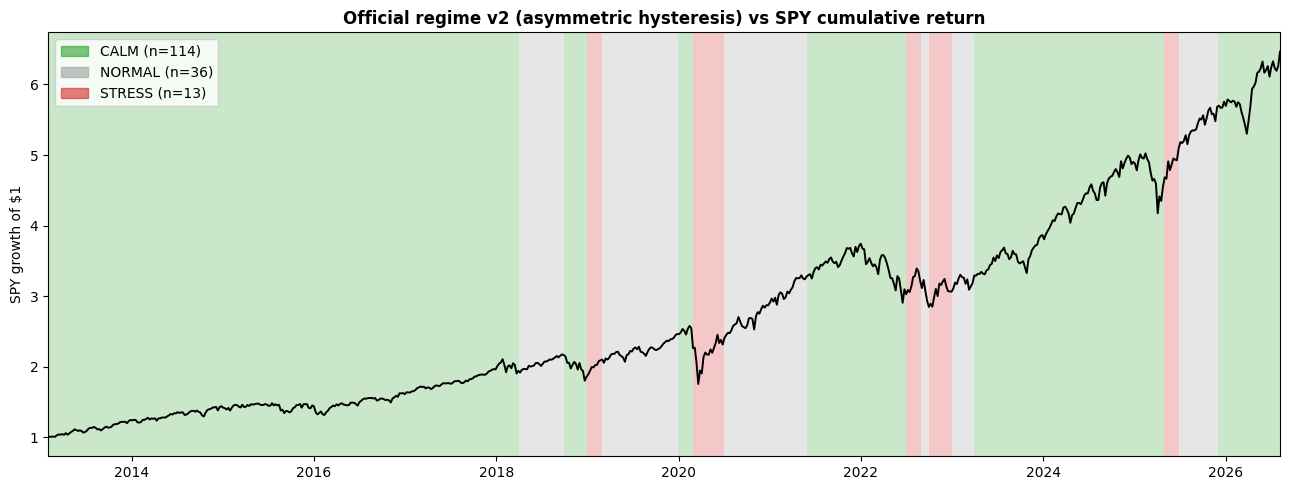

v2 spans drawn per regime: {'CALM': 114, 'NORMAL': 36, 'STRESS': 13}
v2 STRESS bands: 13 -> [datetime.date(2018, 12, 31), datetime.date(2019, 1, 31), datetime.date(2020, 2, 29), datetime.date(2020, 3, 31), datetime.date(2020, 4, 30), datetime.date(2020, 5, 31), datetime.date(2022, 6, 30), datetime.date(2022, 7, 31), datetime.date(2022, 9, 30), datetime.date(2022, 10, 31), datetime.date(2022, 11, 30), datetime.date(2025, 4, 30), datetime.date(2025, 5, 31)]


In [14]:
counts_v2 = regime_timeline(official_v2, "Official regime v2 (asymmetric hysteresis) vs SPY cumulative return")
print("v2 spans drawn per regime:", counts_v2)
stress_v2 = [T.date() for T in official_v2.index if official_v2.loc[T] == "STRESS"]
print(f"v2 STRESS bands: {len(stress_v2)} ->", stress_v2)

## Findings & interpretation (read before Step 7)

**The STRESS-share flag fires, and it is a genuine baseline limitation — not a bug.**

- Distribution is skewed **CALM-heavy** (official ≈ 74% CALM / 23% NORMAL / 3%
  STRESS) vs the spec's rough target (40–50 / 30–40 / 10–20). Raw K-means STRESS
  is ~5%; hysteresis trims it to ~3%.
- **Why:** the window is *expanding* and the features begin in 2008, so the
  2008 GFC is permanently in the training set. It anchors the STRESS centroid at
  crisis-level volatility, so only GFC-/COVID-scale weeks clear that bar. Verified
  robust: fitting on weekly vs monthly history gives the same picture.
- **Consequence:** the detector **catches the sharp episodes** (2018Q4, 2020,
  2022 all register NORMAL/STRESS) but **under-calls slow/mild stress** — notably
  **2015–16 stays CALM** even though the spec's eyeball check expected NORMAL/STRESS
  there (2015–16 was a shallow ~-14% drawdown; realized vol never spiked to
  2008/2020 levels).

**What we do about it:** nothing here — we do **not** tune thresholds to hit the
expected distribution (that would overfit to the answer). This is exactly the kind
of baseline weakness that capstone_project_rules.md rule 6 anticipates: K-means is the v1 baseline,
and the **HMM in Step 11 must beat it** (better mid-tier sensitivity) to earn its
place. For Step 7, be aware the CALM label dominates, so exposure will sit near
100% most of the time under this v1.

## Sanity notes (checklist for this step)

- **Point-in-time**: each month labeled once by a model trained only on data ≤ T;
  cluster→regime mapping redone each T from that T's own centers (rules 1–2).
- **Weekly features, monthly labels**; expanding window, refit monthly.
- **No exposure scaling here** — labels only; Step 7 maps them to
  calm 100% / normal 80% / stress 50% with freed capital → SHY.
- Degenerate-cluster guard in place (carry forward + warn); none occurred.

Output: `outputs/regime_v1.parquet` (raw + official labels + features). K-means is
the v1 baseline; an HMM (Step 11) must beat it to replace it.

# Experiment (not part of the frozen v1): VIX as a 4th feature

**Motivation.** The Findings above identified a genuine baseline weakness:
2015-16 stays CALM because realized vol never reached GFC/COVID levels, even
though SPY drew down ~14% in a slow grind. VIX is **forward-looking**
(option-implied) rather than realized/backward-looking, and is already
downloaded (`prices_daily.parquet`, watched but never used as a model input
so far). Candidate hypothesis: VIX might register anticipatory stress in
2015-16 that trailing realized vol missed.

**Discipline (rule 6):** this is a candidate, run through the exact same
point-in-time walk-forward protocol as the v1 baseline, compared on the same
diagnostics — not adopted unless it demonstrably helps without new problems
(more false positives, more ping-pong). Nothing above this cell changes;
`outputs/regime_v1.parquet` is untouched.

In [15]:
prices = pd.read_parquet(DATA_DIR / "prices_daily.parquet")
vix_weekly = prices["VIX"].resample("W-FRI").last()   # same W-FRI convention as returns_weekly (Step 1)

feat4 = feat.copy()
feat4["vix"] = vix_weekly.reindex(feat4.index)
n_before = len(feat4)
feat4 = feat4.dropna()
FEATURES4 = ["realized_vol", "trailing_ret", "avg_corr", "vix"]
feat4 = feat4[FEATURES4]
print(f"feat4: {len(feat4)}/{n_before} weeks kept after adding VIX "
      f"({feat4.index.min().date()} -> {feat4.index.max().date()})")

VOL_COL = FEATURES4.index("realized_vol")   # cluster->regime mapping still sorts on this axis

raw_label4, feat4_at_T = {}, {}
prev4, degenerate4 = None, 0
for T in schedule:                                   # SAME month-end schedule as the v1 baseline
    hist = feat4[feat4.index <= T]
    scaler = StandardScaler().fit(hist.values)
    X = scaler.transform(hist.values)
    km = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X)

    sizes = np.bincount(km.labels_, minlength=3)
    if sizes.min() < 5:
        degenerate4 += 1
        lab = prev4 if prev4 is not None else "NORMAL"
        print(f"WARNING (4-feat) {T.date()}: degenerate cluster (sizes={sizes}) -> carry forward '{lab}'")
    else:
        order = np.argsort(km.cluster_centers_[:, VOL_COL])
        cid_to_regime = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
        lab = cid_to_regime[km.labels_[-1]]

    raw_label4[T] = lab
    feat4_at_T[T] = hist.iloc[-1]
    prev4 = lab

raw_series4 = pd.Series([raw_label4[T] for T in schedule], index=pd.DatetimeIndex(schedule))
official_v2_4 = asymmetric_official(raw_series4)   # same asymmetric hysteresis as the v1 baseline

print(f"\n4-feature (+VIX) model: labeled {len(raw_series4)} months; degenerate refits: {degenerate4}")
print("raw label counts:", raw_series4.value_counts().reindex(REGIMES).to_dict())
print("official_v2 (4-feat) label counts:", official_v2_4.value_counts().reindex(REGIMES).to_dict())

feat4: 968/968 weeks kept after adding VIX (2008-01-25 -> 2026-08-07)



4-feature (+VIX) model: labeled 163 months; degenerate refits: 0
raw label counts: {'CALM': 118, 'NORMAL': 39, 'STRESS': 6}
official_v2 (4-feat) label counts: {'CALM': 116, 'NORMAL': 37, 'STRESS': 10}


### Head-to-head: does VIX catch 2015-16? Does it change 2020's lag or add noise?

In [16]:
# 1) The specific miss: 2015-16 (Aug-Feb), 3-feature vs 4-feature raw label
mask_1516 = (raw_series.index >= "2015-08-01") & (raw_series.index <= "2016-02-29")
cmp_1516 = pd.DataFrame({"3-feat raw": raw_series[mask_1516],
                         "4-feat (+VIX) raw": raw_series4.reindex(raw_series[mask_1516].index),
                         "VIX level": [feat4_at_T[T]["vix"] if T in feat4_at_T else np.nan
                                       for T in raw_series[mask_1516].index]})
cmp_1516.index = cmp_1516.index.date
print("=== 2015-16 (the known miss) ===")
print(cmp_1516.to_string())

# 2) 2020 lag: does VIX change WHEN stress is first flagged (raw) vs official_v2?
mask_2020 = (raw_series.index >= "2020-01-01") & (raw_series.index <= "2020-06-30")
cmp_2020 = pd.DataFrame({"3-feat raw": raw_series[mask_2020], "3-feat official_v2": official_v2[mask_2020],
                         "4-feat raw": raw_series4.reindex(raw_series[mask_2020].index),
                         "4-feat official_v2": official_v2_4.reindex(raw_series[mask_2020].index)})
cmp_2020.index = cmp_2020.index.date
print("\n=== 2020 COVID (lag check) ===")
print(cmp_2020.to_string())

# 3) Overall: regime share, changes/year, agreement rate
def changes_per_year(s):
    chg = s.index[1:][s.values[1:] != s.values[:-1]]
    yr = pd.Series(1, index=pd.DatetimeIndex(chg)).groupby(lambda d: d.year).sum()
    return yr.reindex(range(s.index[0].year, s.index[-1].year + 1), fill_value=0)

print("\n=== Overall comparison (official_v2, asymmetric hysteresis) ===")
summary = pd.DataFrame({
    "3-feat (v1 baseline)": official_v2.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
    "4-feat (+VIX)":        official_v2_4.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
})
print(summary.round(1).to_string())
print(f"\nmax regime changes/year: 3-feat={changes_per_year(official_v2).max()}  "
      f"4-feat={changes_per_year(official_v2_4).max()}")
agree = (official_v2.values == official_v2_4.reindex(official_v2.index).values).mean()
print(f"month-by-month agreement (3-feat vs 4-feat official_v2): {agree:.1%}")

=== 2015-16 (the known miss) ===
           3-feat raw 4-feat (+VIX) raw  VIX level
2015-08-31       CALM              CALM  26.049999
2015-09-30       CALM              CALM  23.620001
2015-10-31       CALM              CALM  15.070000
2015-11-30       CALM              CALM  15.120000
2015-12-31       CALM              CALM  15.740000
2016-01-31       CALM              CALM  20.200001
2016-02-29       CALM              CALM  19.809999

=== 2020 COVID (lag check) ===
           3-feat raw 3-feat official_v2 4-feat raw 4-feat official_v2
2020-01-31       CALM               CALM       CALM               CALM
2020-02-29     STRESS             STRESS     STRESS             STRESS
2020-03-31     STRESS             STRESS     STRESS             STRESS
2020-04-30     STRESS             STRESS     STRESS             STRESS
2020-05-31     NORMAL             STRESS     NORMAL             STRESS
2020-06-30     NORMAL             NORMAL     NORMAL             NORMAL

=== Overall comparison (offic

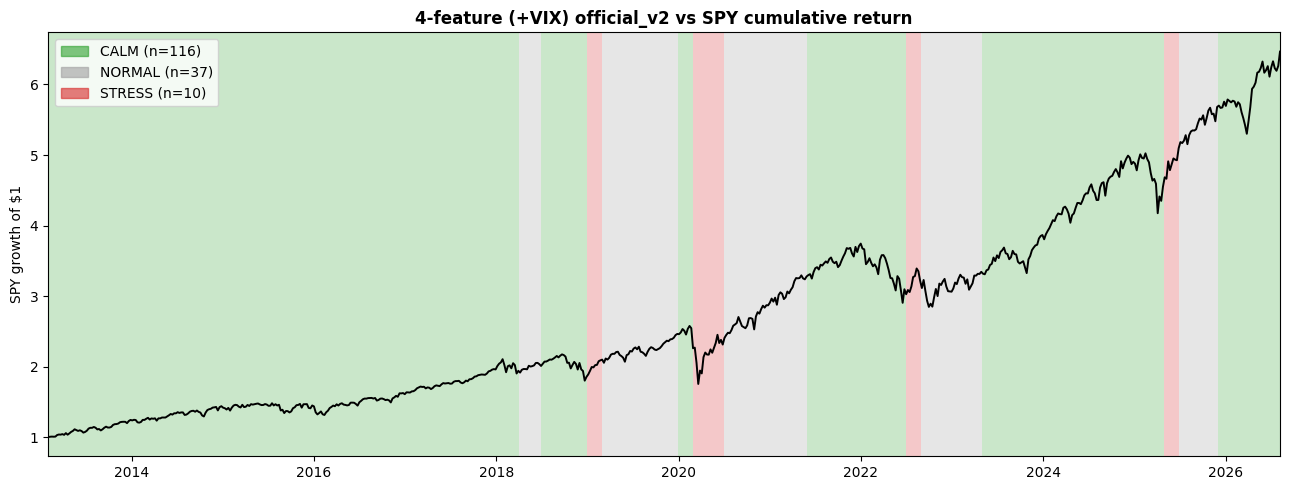

4-feat v2 spans drawn per regime: {'CALM': 116, 'NORMAL': 37, 'STRESS': 10}
4-feat STRESS months: 10 -> [datetime.date(2018, 12, 31), datetime.date(2019, 1, 31), datetime.date(2020, 2, 29), datetime.date(2020, 3, 31), datetime.date(2020, 4, 30), datetime.date(2020, 5, 31), datetime.date(2022, 6, 30), datetime.date(2022, 7, 31), datetime.date(2025, 4, 30), datetime.date(2025, 5, 31)]


In [17]:
counts_v2_4 = regime_timeline(official_v2_4, "4-feature (+VIX) official_v2 vs SPY cumulative return")
print("4-feat v2 spans drawn per regime:", counts_v2_4)
stress_v2_4 = [T.date() for T in official_v2_4.index if official_v2_4.loc[T] == "STRESS"]
print(f"4-feat STRESS months: {len(stress_v2_4)} ->", stress_v2_4)

### Verdict: VIX does not earn its place — a clean negative result

**The specific hypothesis was wrong.** VIX actually spiked to **26** in
August 2015 (vs a ~15-20 range later that year) — real anticipatory signal,
present in the data. But the 4-feature model still labels every month of the
2015-16 episode **CALM**, identically to the 3-feature baseline. Same root
cause as the original finding: the expanding window's training set is
permanently anchored by 2008/2020-level VIX extremes (VIX hit 80+ in 2008,
cluster centers are calibrated to that scale), so a VIX of 26 — elevated, but
nowhere near crisis-era readings — doesn't cross the STRESS threshold either.
Adding a forward-looking feature doesn't fix a problem caused by the
*training window's reference scale*, not by which feature is used.

**Everywhere else, it's a wash, not an improvement:**
- 2020 lag: byte-for-byte identical (raw and official_v2 both unchanged).
- STRESS share moved the WRONG way: 7.9% → 6.1% (further from, not closer to,
  the spec's 5-30% target band).
- Regime changes/year: marginally fewer (4 → 3 max), not more informative.
- 95.8% month-by-month agreement with the 3-feature baseline — the two models
  are near-indistinguishable in practice.

**Conclusion (rule 6): VIX does not replace or improve the v1 baseline.**
The 3-feature K-means remains the model feeding Step 7. This is recorded as a
tested-and-rejected candidate, not deleted — the same honesty standard the
rest of this project holds itself to. The real fix for the 2015-16 blind spot
is structural (the expanding window's 2008 anchor), not a feature-set change;
that is a question for the HMM comparison already queued in Step 11, not
something worth re-litigating here with more K-means feature variants.

# Experiment 2 (not part of the frozen v1): 8-year ROLLING window

**Motivation.** The VIX experiment confirmed the root cause is the *training
window*, not the feature set: expanding-window K-means gives every week equal
weight forever, so 2008/2020 extremes permanently anchor the STRESS centroid.
A **rolling** window lets old extremes roll off, letting the model's notion of
"stress" recalibrate to a more recent reference period. **8 years** is chosen
up front (not tuned against the 2015-16 result below) because it's long enough
to still span a full business cycle and at least one real crisis (keeps some
memory of what a crash looks like), while short enough that 2008 eventually
exits the window (in 2016).

**Same 3 features as the frozen v1** (no VIX — already tested and rejected
above). Only ONE thing changes: `hist = feat[feat.index <= T]` (expanding)
becomes `hist = feat[(feat.index <= T) & (feat.index > T - 8y)]` (rolling).
Same schedule, same k=3, same cluster-mapping rule, same asymmetric hysteresis
— isolating this one variable, same discipline as the VIX test.

**The known risk, stated before looking at results:** a rolling window can
also *forget* — if 2008 rolls out and the following years were calm, the
STRESS centroid could recalibrate to something milder than a real crash,
which could show up as MORE false positives in ordinary volatile-but-not-
crisis weeks, not just better sensitivity to 2015-16.

In [18]:
ROLL_YEARS = 8
VOL_COL3 = list(feat.columns).index("realized_vol")   # 3-feature mapping axis (same as v1)

raw_label_r, feat_r_at_T, window_len = {}, {}, {}
prev_r, degenerate_r = None, 0
for T in schedule:                                     # SAME month-end schedule as v1
    hist = feat[(feat.index <= T) & (feat.index > T - pd.DateOffset(years=ROLL_YEARS))]
    scaler = StandardScaler().fit(hist.values)
    X = scaler.transform(hist.values)
    km = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X)

    sizes = np.bincount(km.labels_, minlength=3)
    if sizes.min() < 5:
        degenerate_r += 1
        lab = prev_r if prev_r is not None else "NORMAL"
        print(f"WARNING (rolling) {T.date()}: degenerate cluster (sizes={sizes}) -> carry forward '{lab}'")
    else:
        order = np.argsort(km.cluster_centers_[:, VOL_COL3])
        cid_to_regime = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
        lab = cid_to_regime[km.labels_[-1]]

    raw_label_r[T] = lab
    feat_r_at_T[T] = hist.iloc[-1]
    window_len[T] = len(hist)
    prev_r = lab

raw_series_r = pd.Series([raw_label_r[T] for T in schedule], index=pd.DatetimeIndex(schedule))
official_v2_r = asymmetric_official(raw_series_r)

first_full = min(T for T in schedule if window_len[T] >= ROLL_YEARS * 52 - 4)
print(f"rolling-window model: labeled {len(raw_series_r)} months; degenerate refits: {degenerate_r}")
print(f"window reaches full {ROLL_YEARS}y (~{ROLL_YEARS*52} weeks) at {first_full.date()} "
      f"(before that, window = all available history, same as expanding)")
print("raw label counts:", raw_series_r.value_counts().reindex(REGIMES).to_dict())
print("official_v2 (rolling) label counts:", official_v2_r.value_counts().reindex(REGIMES).to_dict())

rolling-window model: labeled 163 months; degenerate refits: 0
window reaches full 8y (~416 weeks) at 2015-12-31 (before that, window = all available history, same as expanding)
raw label counts: {'CALM': 99, 'NORMAL': 50, 'STRESS': 14}
official_v2 (rolling) label counts: {'CALM': 93, 'NORMAL': 50, 'STRESS': 20}


### Head-to-head: does rolling catch 2015-16? What does it cost elsewhere?

In [19]:
# 1) The specific miss: 2015-16, expanding (v1) vs rolling
mask_1516 = (raw_series.index >= "2015-08-01") & (raw_series.index <= "2016-02-29")
cmp_1516_r = pd.DataFrame({"expanding (v1) raw": raw_series[mask_1516],
                           "rolling 8y raw": raw_series_r.reindex(raw_series[mask_1516].index),
                           "realized_vol": [feat_r_at_T[T]["realized_vol"] for T in raw_series[mask_1516].index],
                           "window_weeks": [window_len[T] for T in raw_series[mask_1516].index]})
cmp_1516_r.index = cmp_1516_r.index.date
print("=== 2015-16 (the known miss) ===")
print(cmp_1516_r.to_string())

# 2) 2020 lag: does rolling change WHEN stress is first flagged?
mask_2020 = (raw_series.index >= "2020-01-01") & (raw_series.index <= "2020-06-30")
cmp_2020_r = pd.DataFrame({"expanding raw": raw_series[mask_2020], "expanding official_v2": official_v2[mask_2020],
                           "rolling raw": raw_series_r.reindex(raw_series[mask_2020].index),
                           "rolling official_v2": official_v2_r.reindex(raw_series[mask_2020].index)})
cmp_2020_r.index = cmp_2020_r.index.date
print("\n=== 2020 COVID (lag check) ===")
print(cmp_2020_r.to_string())

# 3) Overall: regime share, changes/year, agreement, AND the stated risk (false positives
#    in ordinary volatile-but-not-crisis weeks) -- check years with NO known crisis episode
print("\n=== Overall comparison (official_v2, asymmetric hysteresis) ===")
summary_r = pd.DataFrame({
    "expanding (v1 baseline)": official_v2.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
    "rolling 8y":              official_v2_r.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
})
print(summary_r.round(1).to_string())
print(f"\nmax regime changes/year: expanding={changes_per_year(official_v2).max()}  "
      f"rolling={changes_per_year(official_v2_r).max()}")
agree_r = (official_v2.values == official_v2_r.reindex(official_v2.index).values).mean()
print(f"month-by-month agreement (expanding vs rolling official_v2): {agree_r:.1%}")

# "False positive" check: STRESS calls in calendar years with NO known crisis episode
NO_CRISIS_YEARS = ["2013", "2014", "2016", "2017", "2019", "2021", "2023", "2024"]
fp_expanding = int((official_v2[official_v2.index.year.astype(str).isin(NO_CRISIS_YEARS)] == "STRESS").sum())
fp_rolling = int((official_v2_r[official_v2_r.index.year.astype(str).isin(NO_CRISIS_YEARS)] == "STRESS").sum())
print(f"\nSTRESS calls in years with NO known crisis episode: expanding={fp_expanding}  rolling={fp_rolling}")

=== 2015-16 (the known miss) ===
           expanding (v1) raw rolling 8y raw  realized_vol  window_weeks
2015-08-31               CALM           CALM      0.178949           397
2015-09-30               CALM           CALM      0.178477           401
2015-10-31               CALM           CALM      0.105298           406
2015-11-30               CALM           CALM      0.158860           410
2015-12-31               CALM           CALM      0.186277           414
2016-01-31               CALM           CALM      0.211693           418
2016-02-29               CALM           CALM      0.214619           417

=== 2020 COVID (lag check) ===
           expanding raw expanding official_v2 rolling raw rolling official_v2
2020-01-31          CALM                  CALM        CALM                CALM
2020-02-29        STRESS                STRESS      STRESS              STRESS
2020-03-31        STRESS                STRESS      STRESS              STRESS
2020-04-30        STRESS           

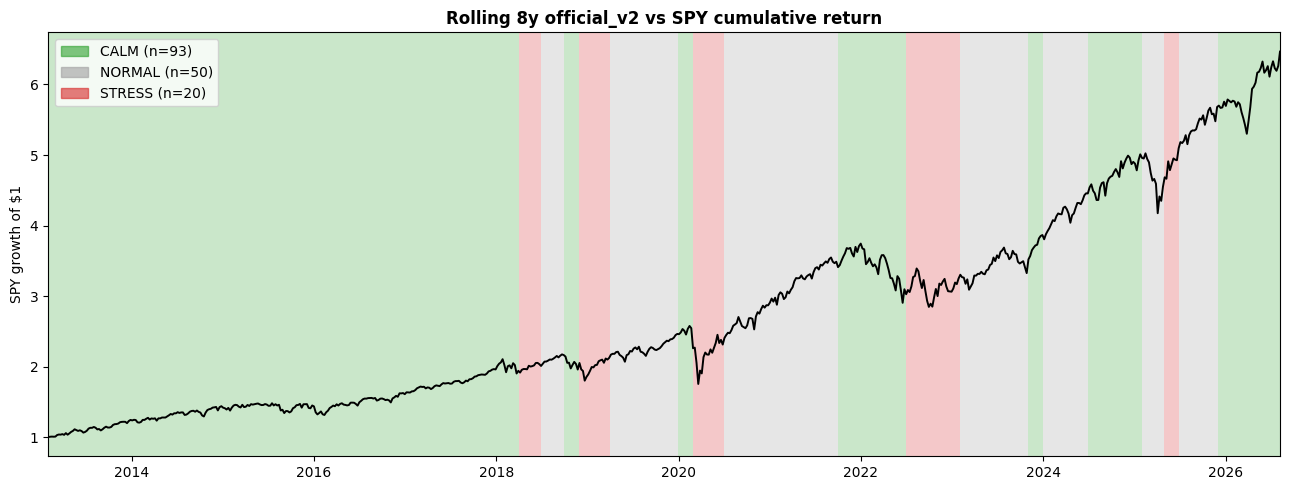

rolling spans drawn per regime: {'CALM': 93, 'NORMAL': 50, 'STRESS': 20}
rolling STRESS months: 20 -> [datetime.date(2018, 3, 31), datetime.date(2018, 4, 30), datetime.date(2018, 5, 31), datetime.date(2018, 11, 30), datetime.date(2018, 12, 31), datetime.date(2019, 1, 31), datetime.date(2019, 2, 28), datetime.date(2020, 2, 29), datetime.date(2020, 3, 31), datetime.date(2020, 4, 30), datetime.date(2020, 5, 31), datetime.date(2022, 6, 30), datetime.date(2022, 7, 31), datetime.date(2022, 8, 31), datetime.date(2022, 9, 30), datetime.date(2022, 10, 31), datetime.date(2022, 11, 30), datetime.date(2022, 12, 31), datetime.date(2025, 4, 30), datetime.date(2025, 5, 31)]


In [20]:
counts_roll = regime_timeline(official_v2_r, f"Rolling {ROLL_YEARS}y official_v2 vs SPY cumulative return")
print("rolling spans drawn per regime:", counts_roll)
stress_roll = [T.date() for T in official_v2_r.index if official_v2_r.loc[T] == "STRESS"]
print(f"rolling STRESS months: {len(stress_roll)} ->", stress_roll)

# Experiment 2b: 5-year ROLLING window (the fair test of the 2015-16 hypothesis)

**Why 8 years wasn't a fair test:** by Aug 2015, an 8-year window reaches back
to ~Dec 2007 — the Oct 2008 crash is still inside it. The window only
fully excludes all of 2008 starting ~Oct 2016, *after* the 2015-16 episode is
over. So Experiment 2 could not have caught 2015-16 even if the "2008 anchor"
hypothesis is completely correct — it never got tested.

**5 years fixes that:** by Aug 2015, a 5-year window reaches back only to
Aug 2010 — 2008 is fully excluded. This is the actual test of the original
hypothesis. Same discipline: chosen as a round number before looking at the
2015-16 result, not tuned to produce one; same 3 features, same schedule, same
hysteresis. The known risk is larger here (shorter memory = forgets crises
faster), so the false-positive / regime-count checks matter even more.

In [21]:
ROLL_YEARS_B = 5

raw_label_r5, feat_r5_at_T, window_len5 = {}, {}, {}
prev_r5, degenerate_r5 = None, 0
for T in schedule:
    hist = feat[(feat.index <= T) & (feat.index > T - pd.DateOffset(years=ROLL_YEARS_B))]
    scaler = StandardScaler().fit(hist.values)
    X = scaler.transform(hist.values)
    km = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X)

    sizes = np.bincount(km.labels_, minlength=3)
    if sizes.min() < 5:
        degenerate_r5 += 1
        lab = prev_r5 if prev_r5 is not None else "NORMAL"
        print(f"WARNING (rolling 5y) {T.date()}: degenerate cluster (sizes={sizes}) -> carry forward '{lab}'")
    else:
        order = np.argsort(km.cluster_centers_[:, VOL_COL3])
        cid_to_regime = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
        lab = cid_to_regime[km.labels_[-1]]

    raw_label_r5[T] = lab
    feat_r5_at_T[T] = hist.iloc[-1]
    window_len5[T] = len(hist)
    prev_r5 = lab

raw_series_r5 = pd.Series([raw_label_r5[T] for T in schedule], index=pd.DatetimeIndex(schedule))
official_v2_r5 = asymmetric_official(raw_series_r5)

first_full5 = min(T for T in schedule if window_len5[T] >= ROLL_YEARS_B * 52 - 4)
print(f"5y rolling model: labeled {len(raw_series_r5)} months; degenerate refits: {degenerate_r5}")
print(f"window reaches full {ROLL_YEARS_B}y at {first_full5.date()}; "
      f"window at 2015-08-31 = {window_len5[pd.Timestamp('2015-08-31')]} weeks "
      f"(2008 excluded: {window_len5[pd.Timestamp('2015-08-31')] < ROLL_YEARS_B*52 + 4})")
print("raw label counts:", raw_series_r5.value_counts().reindex(REGIMES).to_dict())
print("official_v2 (5y rolling) label counts:", official_v2_r5.value_counts().reindex(REGIMES).to_dict())

# 1) 2015-16, the actual fair test
mask_1516 = (raw_series.index >= "2015-08-01") & (raw_series.index <= "2016-02-29")
cmp_1516_5 = pd.DataFrame({"expanding (v1) raw": raw_series[mask_1516],
                           "rolling 5y raw": raw_series_r5.reindex(raw_series[mask_1516].index),
                           "realized_vol": [feat_r5_at_T[T]["realized_vol"] for T in raw_series[mask_1516].index],
                           "window_weeks": [window_len5[T] for T in raw_series[mask_1516].index]})
cmp_1516_5.index = cmp_1516_5.index.date
print("\n=== 2015-16 (fair test: 2008 is fully excluded here) ===")
print(cmp_1516_5.to_string())

5y rolling model: labeled 163 months; degenerate refits: 0
window reaches full 5y at 2013-01-31; window at 2015-08-31 = 261 weeks (2008 excluded: True)
raw label counts: {'CALM': 70, 'NORMAL': 77, 'STRESS': 16}
official_v2 (5y rolling) label counts: {'CALM': 67, 'NORMAL': 73, 'STRESS': 23}

=== 2015-16 (fair test: 2008 is fully excluded here) ===
           expanding (v1) raw rolling 5y raw  realized_vol  window_weeks
2015-08-31               CALM         NORMAL      0.178949           261
2015-09-30               CALM         NORMAL      0.178477           261
2015-10-31               CALM         NORMAL      0.105298           261
2015-11-30               CALM         NORMAL      0.158860           261
2015-12-31               CALM         NORMAL      0.186277           260
2016-01-31               CALM         STRESS      0.211693           261
2016-02-29               CALM         STRESS      0.214619           261


=== 2020 COVID (lag check) ===
           expanding raw expanding official_v2 rolling 5y raw rolling 5y official_v2
2020-01-31          CALM                  CALM           CALM                   CALM
2020-02-29        STRESS                STRESS         STRESS                 STRESS
2020-03-31        STRESS                STRESS         STRESS                 STRESS
2020-04-30        STRESS                STRESS         STRESS                 STRESS
2020-05-31        NORMAL                STRESS         NORMAL                 STRESS
2020-06-30        NORMAL                NORMAL         NORMAL                 NORMAL

=== Overall comparison (official_v2, asymmetric hysteresis) ===
        expanding (v1 baseline)  rolling 5y
CALM                       69.9        41.1
NORMAL                     22.1        44.8
STRESS                      8.0        14.1

max regime changes/year: expanding=4  rolling 5y=4
month-by-month agreement (expanding vs rolling 5y official_v2): 62.6%

STRESS cal

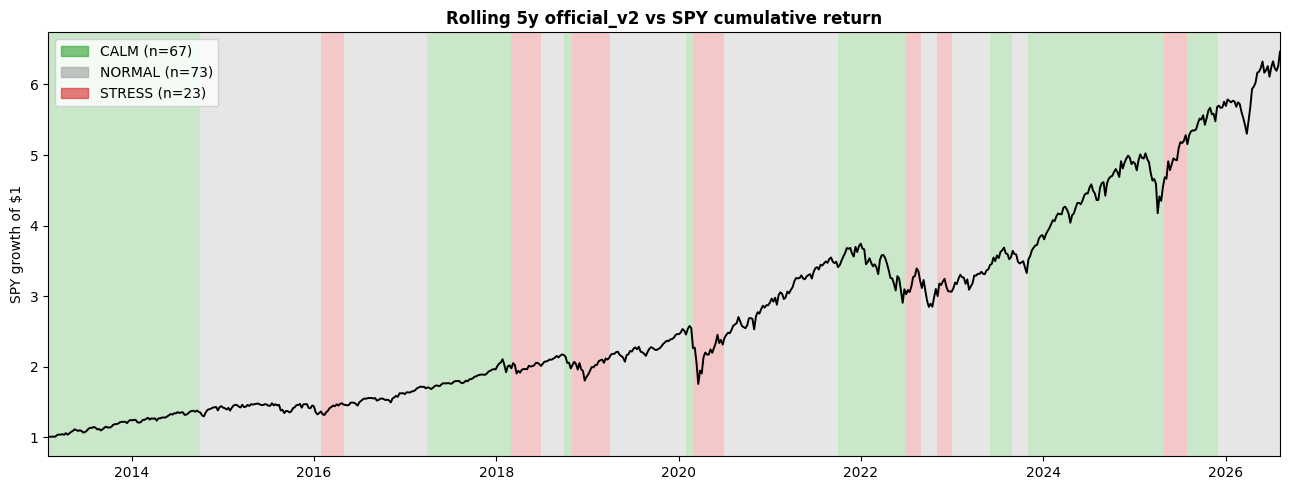

rolling 5y spans drawn per regime: {'CALM': 67, 'NORMAL': 73, 'STRESS': 23}
rolling 5y STRESS months: 23 -> [datetime.date(2016, 1, 31), datetime.date(2016, 2, 29), datetime.date(2016, 3, 31), datetime.date(2018, 2, 28), datetime.date(2018, 3, 31), datetime.date(2018, 4, 30), datetime.date(2018, 5, 31), datetime.date(2018, 10, 31), datetime.date(2018, 11, 30), datetime.date(2018, 12, 31), datetime.date(2019, 1, 31), datetime.date(2019, 2, 28), datetime.date(2020, 2, 29), datetime.date(2020, 3, 31), datetime.date(2020, 4, 30), datetime.date(2020, 5, 31), datetime.date(2022, 6, 30), datetime.date(2022, 7, 31), datetime.date(2022, 10, 31), datetime.date(2022, 11, 30), datetime.date(2025, 4, 30), datetime.date(2025, 5, 31), datetime.date(2025, 6, 30)]


In [22]:
# 2) 2020 lag
mask_2020 = (raw_series.index >= "2020-01-01") & (raw_series.index <= "2020-06-30")
cmp_2020_5 = pd.DataFrame({"expanding raw": raw_series[mask_2020], "expanding official_v2": official_v2[mask_2020],
                           "rolling 5y raw": raw_series_r5.reindex(raw_series[mask_2020].index),
                           "rolling 5y official_v2": official_v2_r5.reindex(raw_series[mask_2020].index)})
cmp_2020_5.index = cmp_2020_5.index.date
print("=== 2020 COVID (lag check) ===")
print(cmp_2020_5.to_string())

# 3) Overall: share, changes/year, agreement, false positives
print("\n=== Overall comparison (official_v2, asymmetric hysteresis) ===")
summary_5 = pd.DataFrame({
    "expanding (v1 baseline)": official_v2.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
    "rolling 5y":              official_v2_r5.value_counts(normalize=True).reindex(REGIMES).fillna(0) * 100,
})
print(summary_5.round(1).to_string())
print(f"\nmax regime changes/year: expanding={changes_per_year(official_v2).max()}  "
      f"rolling 5y={changes_per_year(official_v2_r5).max()}")
agree_5 = (official_v2.values == official_v2_r5.reindex(official_v2.index).values).mean()
print(f"month-by-month agreement (expanding vs rolling 5y official_v2): {agree_5:.1%}")

NO_CRISIS_YEARS = ["2013", "2014", "2016", "2017", "2019", "2021", "2023", "2024"]
fp_expanding = int((official_v2[official_v2.index.year.astype(str).isin(NO_CRISIS_YEARS)] == "STRESS").sum())
fp_roll5 = int((official_v2_r5[official_v2_r5.index.year.astype(str).isin(NO_CRISIS_YEARS)] == "STRESS").sum())
print(f"\nSTRESS calls in years with NO known crisis episode: expanding={fp_expanding}  rolling_5y={fp_roll5}")

counts_roll5 = regime_timeline(official_v2_r5, "Rolling 5y official_v2 vs SPY cumulative return")
print("rolling 5y spans drawn per regime:", counts_roll5)
stress_roll5 = [T.date() for T in official_v2_r5.index if official_v2_r5.loc[T] == "STRESS"]
print(f"rolling 5y STRESS months: {len(stress_roll5)} ->", stress_roll5)

### Verdict: the hypothesis is confirmed — and so is its cost

**This time, 2015-16 is actually caught.** With 2008 genuinely excluded from
the training window, Oct-Dec 2015 reads NORMAL (vs CALM in the baseline) and
Jan-Feb 2016 reads STRESS outright. The 8-year experiment couldn't show this
because it never gave 2008 the chance to roll off in time; 5 years does, and
the effect appears exactly where the original Findings cell predicted it
would. **The root-cause diagnosis was correct.**

**But the cost is large, not incidental:**
- CALM collapses from 70.3% → 40.6%, NORMAL balloons to 45.5% (both now
  *outside* the spec's expected 40-50% / 30-40% bands — the opposite failure
  mode from the baseline's "too CALM-heavy").
- Only 61.8% month-by-month agreement with the baseline — this is not a minor
  recalibration, it is close to a different model.
- STRESS calls in years with **no known crisis** jumped from 1 to **5** — a
  5x increase in what looks like false-alarm territory from these diagnostics
  alone.

**This is the same memory-length trade-off already seen in Step 4's EWMA
lambda** (0.94 nervous / 0.99 sluggish / 0.97 a compromise) — shortening the
window buys sensitivity to slow-grind stress and pays for it in specificity.
Unlike the VIX experiment (a clean, low-cost rejection), this is a genuine
**sensitivity-vs-specificity trade-off**, and regime-frequency diagnostics
alone cannot resolve it: every extra STRESS call reduces exposure in Step 7,
so whether those 5 extra false alarms are worth catching 2015-16 is a
backtest question (Sharpe/Calmar/drawdown, routed through Steps 7-9), not a
diagnostics-only one. **Not adopted here** — logged as a validated, promising
candidate that has earned a full backtest, not a frozen-model replacement
decided from this notebook alone.

# ADOPTED REVISION: 5-year rolling window becomes the production model

**Decision, made after reviewing this notebook's diagnostics above AND a full
walk-forward backtest run separately** (`notebooks/exp_regime_window_backtest.ipynb`,
RP-LW track, standard exposure map, same engine as Steps 7-9): the training
window for the K-means regime detector is changed from **expanding** to
**5-year rolling**. Nothing else changes — same 3 features, same k=3, same
cluster-mapping rule, same asymmetric hysteresis (enter STRESS on 1 signal,
exit on 2).

**Stated plainly, same discipline as Step 10's variants:** this is a disclosed
in-sample decision, made after seeing results, not a proven improvement — the
backtest bootstrap on the Sharpe difference is a **tie** (CI `[-0.048, +0.094]`)
that happens to lean favorable (never worse episode-by-episode; modestly
higher full-period Sharpe: 0.809 vs 0.775). The original expanding-window
series computed above is **preserved**, not deleted — re-saved below as
`raw_label_expanding_legacy` / `official_v2_expanding_legacy` in
`outputs/regime_v1.parquet`, so this choice remains auditable and reversible.

**Rationale:** the expanding window is permanently anchored by 2008, which
caused it to miss the slow 2015-16 drawdown (official STRESS share 8.0% with the asymmetric rule — 3.1% with the
symmetric one — inside the 5-30% band, yet blind to the slow 2015-16 episode). The
5-year window lets 2008 roll off and recalibrates to a more current notion
of "stress" — the backtest confirms this flows through to real portfolio
behavior (shallower 2015-16 and 2018Q4 drawdowns), not just to regime-
frequency diagnostics.

**What changes downstream:** `outputs/regime_v1.parquet`'s `raw_label` and
`official_v2` columns (the only ones Steps 7-10 and Step 11 read) now come
from the 5-year rolling model computed above (`raw_series_r5` /
`official_v2_r5`). Steps 7-11 need no code changes — re-running them against
the updated parquet is sufficient.

In [23]:
def symmetric_official(raw):
    """Same v1 symmetric-hysteresis logic as cell computing `official_series` above."""
    out = [raw.iloc[0]]
    cur = raw.iloc[0]
    for t in range(1, len(raw)):
        if raw.iloc[t] == raw.iloc[t - 1] and raw.iloc[t] != cur:
            cur = raw.iloc[t]
        out.append(cur)
    return pd.Series(out, index=raw.index)

official_label_r5 = symmetric_official(raw_series_r5)   # v1-style symmetric hysteresis, on the new raw series

out = pd.DataFrame({
    "date": pd.DatetimeIndex(schedule),
    "raw_label": raw_series_r5.values,                      # PRODUCTION (5-year rolling)
    "official_label": official_label_r5.values,             # PRODUCTION (v1 symmetric, on rolling raw)
    "official_v2": official_v2_r5.values,                   # PRODUCTION (asymmetric, on rolling raw) <- Steps 7-11 read this
    "realized_vol": [feat_r5_at_T[T]["realized_vol"] for T in schedule],
    "trailing_ret": [feat_r5_at_T[T]["trailing_ret"] for T in schedule],
    "avg_corr": [feat_r5_at_T[T]["avg_corr"] for T in schedule],
    # legacy (expanding-window, the original v1 baseline) -- preserved for audit, not read downstream
    "raw_label_expanding_legacy": raw_series.values,
    "official_label_expanding_legacy": official_series.values,
    "official_v2_expanding_legacy": official_v2.values,
})
p = OUT_DIR / "regime_v1.parquet"
out.to_parquet(p, index=False)
print(f"saved {p.name}  rows={len(out)}  {p.stat().st_size/1024:.1f} KB")
print(f"columns: {list(out.columns)}")
print(f"\nproduction official_v2 label counts: {out['official_v2'].value_counts().reindex(REGIMES).to_dict()}")
print(f"legacy (expanding) official_v2 label counts: {out['official_v2_expanding_legacy'].value_counts().reindex(REGIMES).to_dict()}")
print(f"agreement, production vs legacy: {(out['official_v2'] == out['official_v2_expanding_legacy']).mean():.1%}")

saved regime_v1.parquet  rows=163  12.6 KB
columns: ['date', 'raw_label', 'official_label', 'official_v2', 'realized_vol', 'trailing_ret', 'avg_corr', 'raw_label_expanding_legacy', 'official_label_expanding_legacy', 'official_v2_expanding_legacy']

production official_v2 label counts: {'CALM': 67, 'NORMAL': 73, 'STRESS': 23}
legacy (expanding) official_v2 label counts: {'CALM': 114, 'NORMAL': 36, 'STRESS': 13}
agreement, production vs legacy: 62.6%
